# Loading data

In [33]:
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt

project_root = Path("..")
%matplotlib inline


# Notebook is located under 10_code
project_root = Path("..")

# Left file 2000-2010
input_path = project_root / "00_data" / "processed" / "new_master_county_year_panel.csv"

# load the data
df = pd.read_csv(input_path)

df = df[["state", "year","county", "overdoses_per_100k", "mme_per_capita"]].copy()

###############################################################################################################

# Mortality Part

## 1. Define plot functions (replace NaN value + plot)

In [34]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_did_for_state(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    nan_strategy="drop",
):
    """
    Draws a Difference-in-Differences style plot for one treated state
    and a group of control states, with configurable NaN handling.

    NaN strategies:
    - "drop":        leave NaN as is (they will be dropped later)
    - "mean":        fill NaN with the state-specific mean
    - "median":      fill NaN with the state-specific median
    - "ffill":       forward fill within each time series
                     (within each county if county column exists,
                      otherwise within each state)
    - "bfill":       backward fill within each time series
                     (within each county if county column exists,
                      otherwise within each state)
    - "interpolate": linear interpolation within each time series
                     (within each county if county column exists,
                      otherwise within each state)
    """

    # --------------------------
    # 1. Normalize state codes
    # --------------------------
    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Keep only treated + control states
    use_states = [treated_state] + control_states
    panel = df[df["state"].isin(use_states)].copy()

    # Detect whether we have county-level data
    county_col = "county" if "county" in panel.columns else None

    # -----------------------------------------
    # 2. NaN Handling at the panel level
    # -----------------------------------------
    if nan_strategy != "drop":
        # For mean/median, use state-specific averages
        if nan_strategy == "mean":
            state_g = panel.groupby("state")[rate_col]
            panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))

        elif nan_strategy == "median":
            state_g = panel.groupby("state")[rate_col]
            panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))

        else:
            # For time-series methods, work along sorted time within each unit
            if county_col is not None:
                # county-level panel: sort by state, county, year
                panel = panel.sort_values(["state", county_col, "year"])
                group_cols = ["state", county_col]
            else:
                # state-level panel: sort by state, year
                panel = panel.sort_values(["state", "year"])
                group_cols = ["state"]

            g = panel.groupby(group_cols)[rate_col]

            if nan_strategy == "ffill":
                panel[rate_col] = g.transform(lambda s: s.ffill())
            elif nan_strategy == "bfill":
                panel[rate_col] = g.transform(lambda s: s.bfill())
            elif nan_strategy == "interpolate":
                panel[rate_col] = g.transform(lambda s: s.interpolate(method="linear"))
            else:
                raise ValueError("Invalid nan_strategy choice.")
    # if "drop", we do nothing here and let NaNs be dropped later.

    # ----------------------------------------------------
    # 3. Aggregate to state-year level (from counties)
    # ----------------------------------------------------
    state_year = (
        panel.groupby(["state", "year"], as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )

    # Drop any remaining NaNs in the aggregated rate
    state_year = state_year.dropna(subset=["rate"])

    # ----------------------------------------------------
    # 4. Build treated dummy and aggregate to group-year
    # ----------------------------------------------------
    state_year["treated"] = (state_year["state"] == treated_state).astype(int)

    # Average across all states within each group (treated vs control)
    group_year = state_year.groupby(["treated", "year"], as_index=False)["rate"].mean()

    # Restrict to the pre/post windows
    pre_mask = (group_year["year"] >= policy_year - pre_window) & (
        group_year["year"] < policy_year
    )
    post_mask = (group_year["year"] >= policy_year) & (
        group_year["year"] <= policy_year + post_window
    )

    pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
    pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
    post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
    post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

    if (
        pre_treated.empty
        or pre_control.empty
        or post_treated.empty
        or post_control.empty
    ):
        print("Not enough data for given windows / states.")
        return

    # ---------------------------------------------
    # 5. Helper to fit linear trend + 95% CI
    # ---------------------------------------------
    def fit_segment(seg_df):
        """
        Fits a simple OLS: rate ~ year for a segment (pre or post),
        and returns predicted mean and 95% confidence interval.
        """
        seg_df = seg_df.dropna(subset=["rate"])
        X = sm.add_constant(seg_df["year"])
        model = sm.OLS(seg_df["rate"], X).fit()
        preds = model.get_prediction(X)
        mean = preds.predicted_mean
        ci = preds.conf_int(alpha=0.05)
        lower = ci[:, 0]
        upper = ci[:, 1]
        return mean, lower, upper

    tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
    tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
    co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
    co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

    # ---------------------------------------------
    # 6. Plot DiD-style figure
    # ---------------------------------------------
    plt.figure(figsize=(10, 4))

    # Treated group: pre period (blue)
    x_pre_tr = pre_treated["year"].to_numpy()
    plt.plot(
        x_pre_tr,
        tr_pre_mean,
        color="blue",
        label=f"Test State ({treated_state}) - Pre ({nan_strategy})",
    )
    plt.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

    # Treated group: post period (blue)
    x_post_tr = post_treated["year"].to_numpy()
    plt.plot(x_post_tr, tr_post_mean, color="blue")
    plt.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

    # Control group: pre period (red)
    x_pre_co = pre_control["year"].to_numpy()
    ctrl_label = "Control States (" + ", ".join(control_states) + ")"
    plt.plot(x_pre_co, co_pre_mean, color="red", label=ctrl_label + " - Pre")
    plt.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

    # Control group: post period (red)
    x_post_co = post_control["year"].to_numpy()
    plt.plot(x_post_co, co_post_mean, color="red")
    plt.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

    # Vertical policy line
    plt.axvline(policy_year, color="black", linestyle="--")

    # Axis labels and title
    plt.title(
        f"Difference-in-Difference Analysis for {treated_state} ({nan_strategy} NaN handling)"
    )
    plt.xlabel("Years")
    plt.ylabel(rate_col)

    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------
    # 7. Print a simple numeric DiD estimate
    # ---------------------------------------------
    pre_tr_level = pre_treated["rate"].mean()
    post_tr_level = post_treated["rate"].mean()
    pre_co_level = pre_control["rate"].mean()
    post_co_level = post_control["rate"].mean()

    did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)
    print(
        f"Simple DiD estimate for {treated_state} ({nan_strategy}): "
        f"{did_estimate:.3f} in units of {rate_col}."
    )

## 2. Compare different NaN value dealing ways (bigger plots)

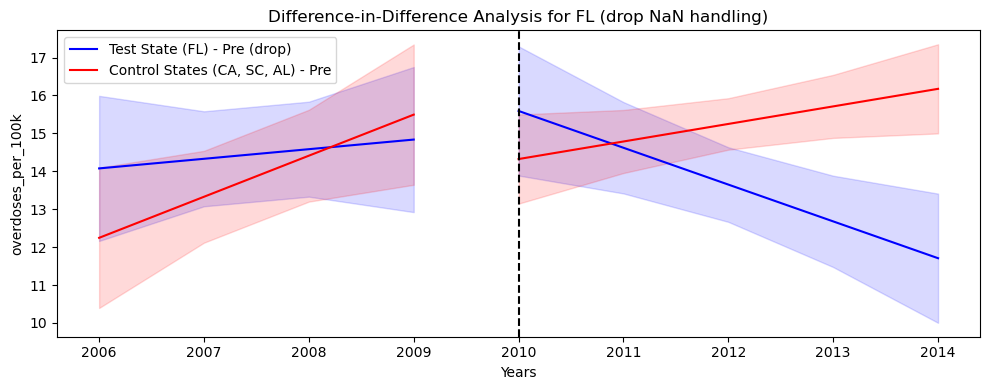

Simple DiD estimate for FL (drop): -2.185 in units of overdoses_per_100k.


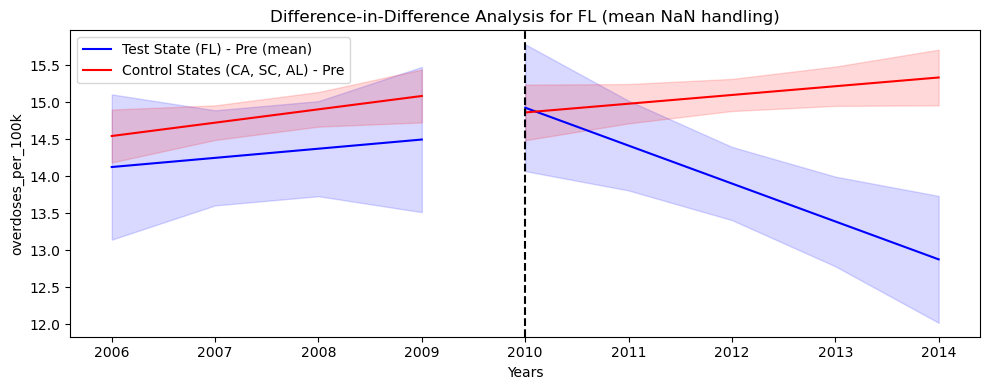

Simple DiD estimate for FL (mean): -0.693 in units of overdoses_per_100k.


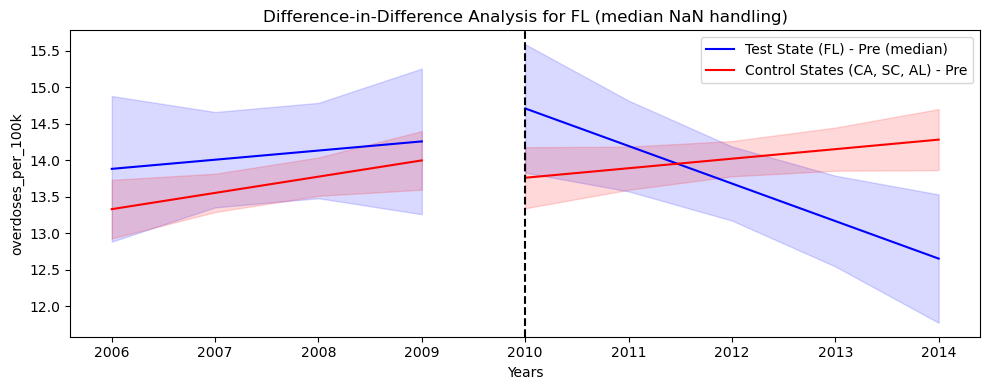

Simple DiD estimate for FL (median): -0.746 in units of overdoses_per_100k.


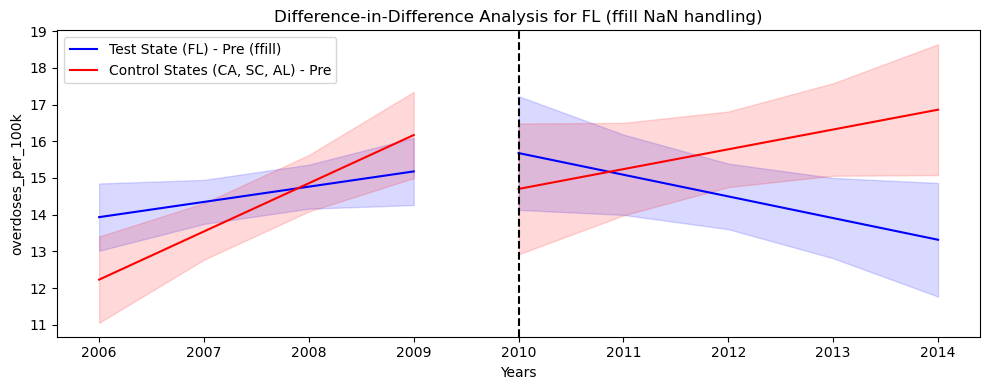

Simple DiD estimate for FL (ffill): -1.639 in units of overdoses_per_100k.


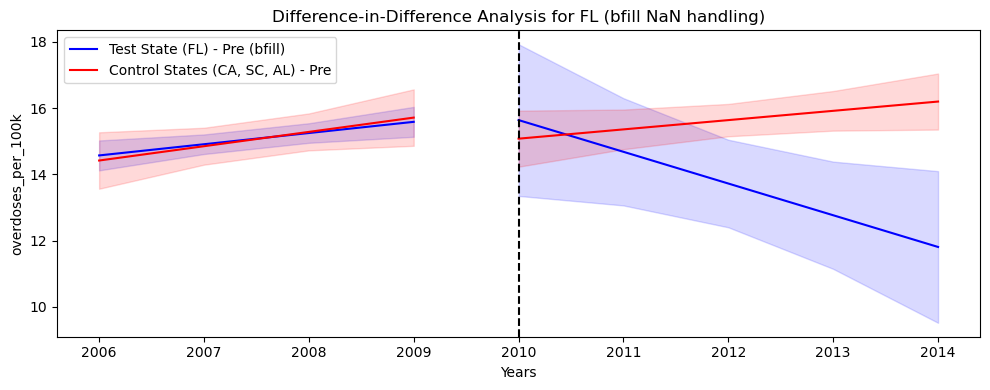

Simple DiD estimate for FL (bfill): -1.927 in units of overdoses_per_100k.


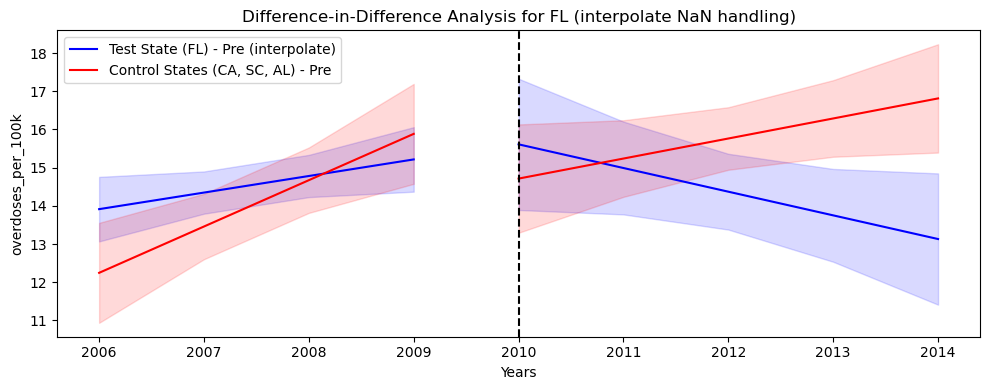

Simple DiD estimate for FL (interpolate): -1.892 in units of overdoses_per_100k.


In [35]:
# Florida
# 1. drop
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="drop",
)

# 2. mean
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="mean",
)

# 3. median
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="median",
)

# 4. ffill
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    nan_strategy="interpolate",
)

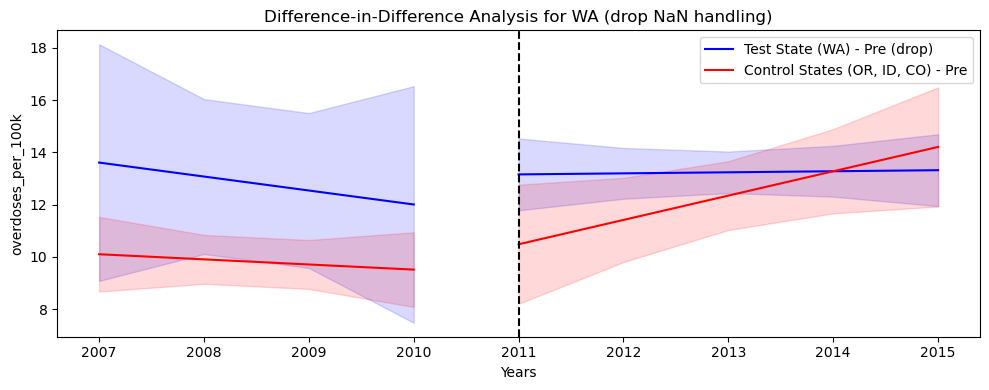

Simple DiD estimate for WA (drop): -2.106 in units of overdoses_per_100k.


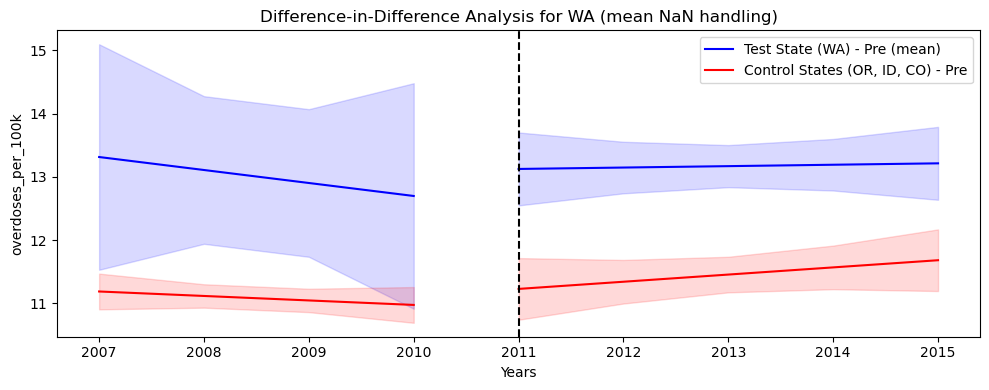

Simple DiD estimate for WA (mean): -0.210 in units of overdoses_per_100k.


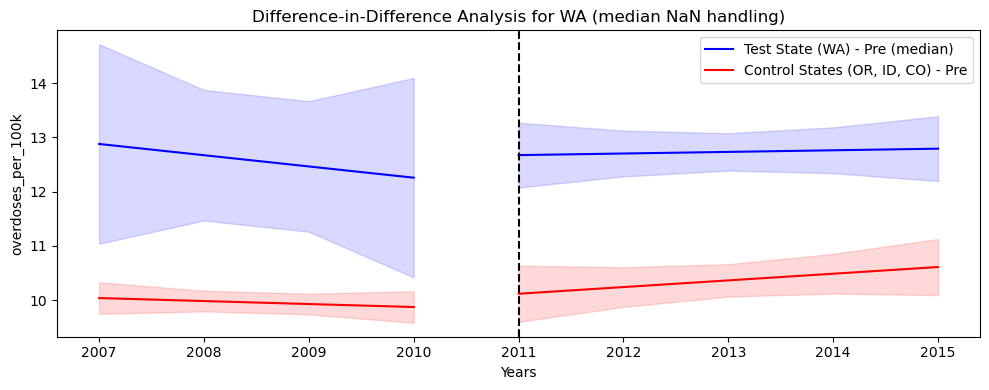

Simple DiD estimate for WA (median): -0.243 in units of overdoses_per_100k.


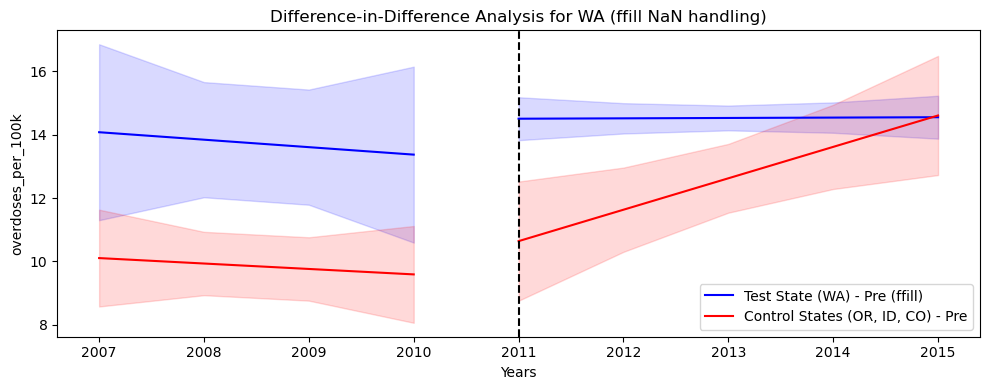

Simple DiD estimate for WA (ffill): -1.973 in units of overdoses_per_100k.


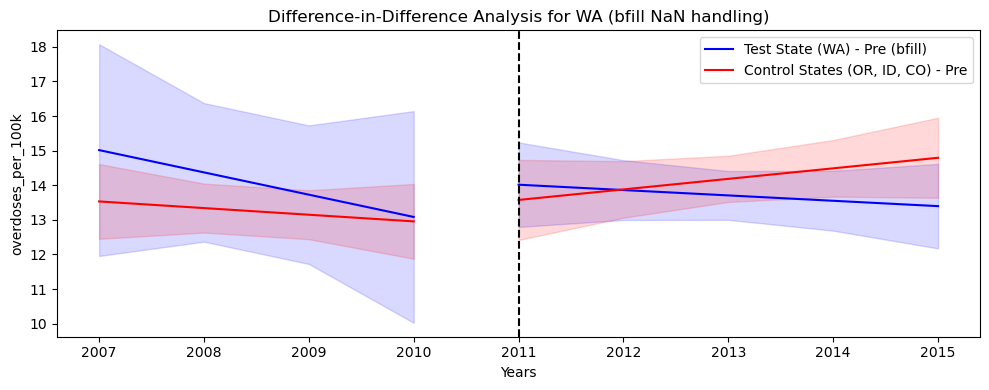

Simple DiD estimate for WA (bfill): -1.284 in units of overdoses_per_100k.


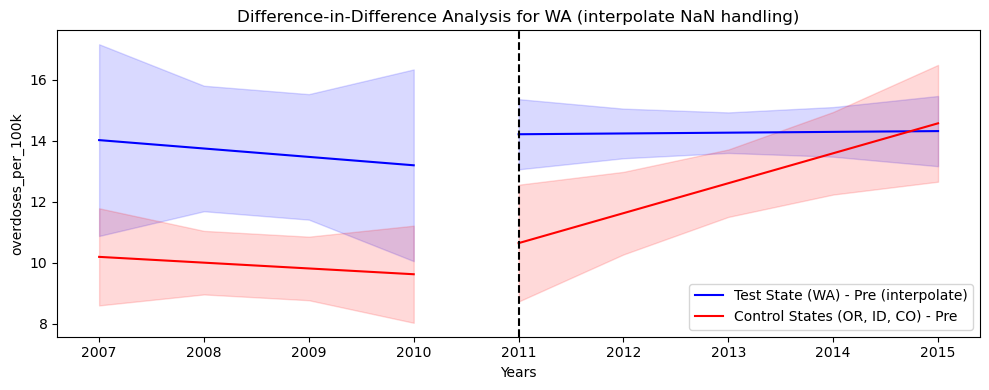

Simple DiD estimate for WA (interpolate): -2.045 in units of overdoses_per_100k.


In [36]:
# Washington
# 1. drop
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="drop",
)

# 2. mean
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="mean",
)

# 3. median
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="median",
)

# 4. ffill
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    nan_strategy="interpolate",
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [37]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_did_grid(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
):
    """
    Draw 6 DiD plots (one for each NaN strategy) in a 3x2 grid.

    NaN strategies:
      - "drop":        leave NaN as is (they will be dropped later)
      - "mean":        fill NaN with the state-specific mean
      - "median":      fill NaN with the state-specific median
      - "ffill":       forward fill within each time series
                       (within state+county if county column exists,
                        otherwise within state)
      - "bfill":       backward fill within each time series
                       (within state+county if county column exists,
                        otherwise within state)
      - "interpolate": linear interpolation within each time series
                       (within state+county if county column exists,
                        otherwise within state)
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    # Normalize state codes
    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Use treated + control states only, for plotting and y-axis scaling
    use_states = [treated_state] + control_states
    subset = df[df["state"].isin(use_states)].copy()

    # Detect county column (for panel data)
    county_col = "county" if "county" in subset.columns else None

    # y-axis scaling based on all non-missing values in these states
    all_values = subset[rate_col].dropna()
    y_min, y_max = all_values.min(), all_values.max()

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        panel = subset.copy()

        # ---------- NaN handling ----------
        if strat != "drop":
            # For mean / median, use state-specific averages
            if strat in ["mean", "median"]:
                state_g = panel.groupby("state")[rate_col]

                if strat == "mean":
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))
                elif strat == "median":
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))
            else:
                # Time-series methods: ffill, bfill, interpolate
                # Work within each unit's time series (state+county or state)
                if county_col is not None:
                    panel = panel.sort_values(["state", county_col, "year"])
                    group_cols = ["state", county_col]
                else:
                    panel = panel.sort_values(["state", "year"])
                    group_cols = ["state"]

                g = panel.groupby(group_cols)[rate_col]

                if strat == "ffill":
                    panel[rate_col] = g.transform(lambda s: s.ffill())
                elif strat == "bfill":
                    panel[rate_col] = g.transform(lambda s: s.bfill())
                elif strat == "interpolate":
                    panel[rate_col] = g.transform(
                        lambda s: s.interpolate(method="linear")
                    )
                else:
                    raise ValueError(f"Invalid nan_strategy: {strat}")

        # ---------- aggregate to state-year ----------
        state_year = (
            panel.groupby(["state", "year"], as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # treated indicator
        state_year["treated"] = (state_year["state"] == treated_state).astype(int)

        # group averages (treated vs control)
        group_year = state_year.groupby(["treated", "year"], as_index=False)[
            "rate"
        ].mean()

        # pre / post masks
        pre_mask = (group_year["year"] >= policy_year - pre_window) & (
            group_year["year"] < policy_year
        )
        post_mask = (group_year["year"] >= policy_year) & (
            group_year["year"] <= policy_year + post_window
        )

        pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
        pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
        post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
        post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

        if (
            pre_treated.empty
            or pre_control.empty
            or post_treated.empty
            or post_control.empty
        ):
            ax.set_title(f"{strat} (not enough data)")
            ax.axis("off")
            continue

        # helper: OLS + CI
        def fit_segment(seg_df):
            """
            Fits OLS: rate ~ year for a given segment (pre / post),
            returns predicted mean and 95% confidence interval.
            """
            seg_df = seg_df.dropna(subset=["rate"])
            X = sm.add_constant(seg_df["year"])
            model = sm.OLS(seg_df["rate"], X).fit()
            preds = model.get_prediction(X)
            mean = preds.predicted_mean
            ci = preds.conf_int(alpha=0.05)
            lower = ci[:, 0]
            upper = ci[:, 1]
            return mean, lower, upper

        tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
        tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
        co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
        co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

        # ---------- plot in this axis ----------
        x_pre_tr = pre_treated["year"].to_numpy()
        x_post_tr = post_treated["year"].to_numpy()
        x_pre_co = pre_control["year"].to_numpy()
        x_post_co = post_control["year"].to_numpy()

        # treated: blue
        ax.plot(x_pre_tr, tr_pre_mean, color="blue", label="Treated - Pre")
        ax.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

        ax.plot(
            x_post_tr, tr_post_mean, color="blue", linestyle="-", label="Treated - Post"
        )
        ax.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

        # control: red
        ax.plot(x_pre_co, co_pre_mean, color="red", label="Control - Pre")
        ax.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

        ax.plot(
            x_post_co, co_post_mean, color="red", linestyle="-", label="Control - Post"
        )
        ax.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

        # policy line
        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(f"{strat}", fontsize=11)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

        # optional: smaller legend inside each subplot
        ax.legend(fontsize=8, loc="best")

        # simple DiD estimate (for text / debugging)
        pre_tr_level = pre_treated["rate"].mean()
        post_tr_level = post_treated["rate"].mean()
        pre_co_level = pre_control["rate"].mean()
        post_co_level = post_control["rate"].mean()
        did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)
        print(
            f"{treated_state} - {strat}: DiD estimate = {did_estimate:.3f} "
            f"in units of {rate_col}"
        )

    fig.suptitle(f"DiD for {treated_state} (6 NaN strategies)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

FL - drop: DiD estimate = -2.185 in units of overdoses_per_100k
FL - mean: DiD estimate = -0.693 in units of overdoses_per_100k
FL - median: DiD estimate = -0.746 in units of overdoses_per_100k
FL - ffill: DiD estimate = -1.639 in units of overdoses_per_100k
FL - bfill: DiD estimate = -1.927 in units of overdoses_per_100k
FL - interpolate: DiD estimate = -1.892 in units of overdoses_per_100k


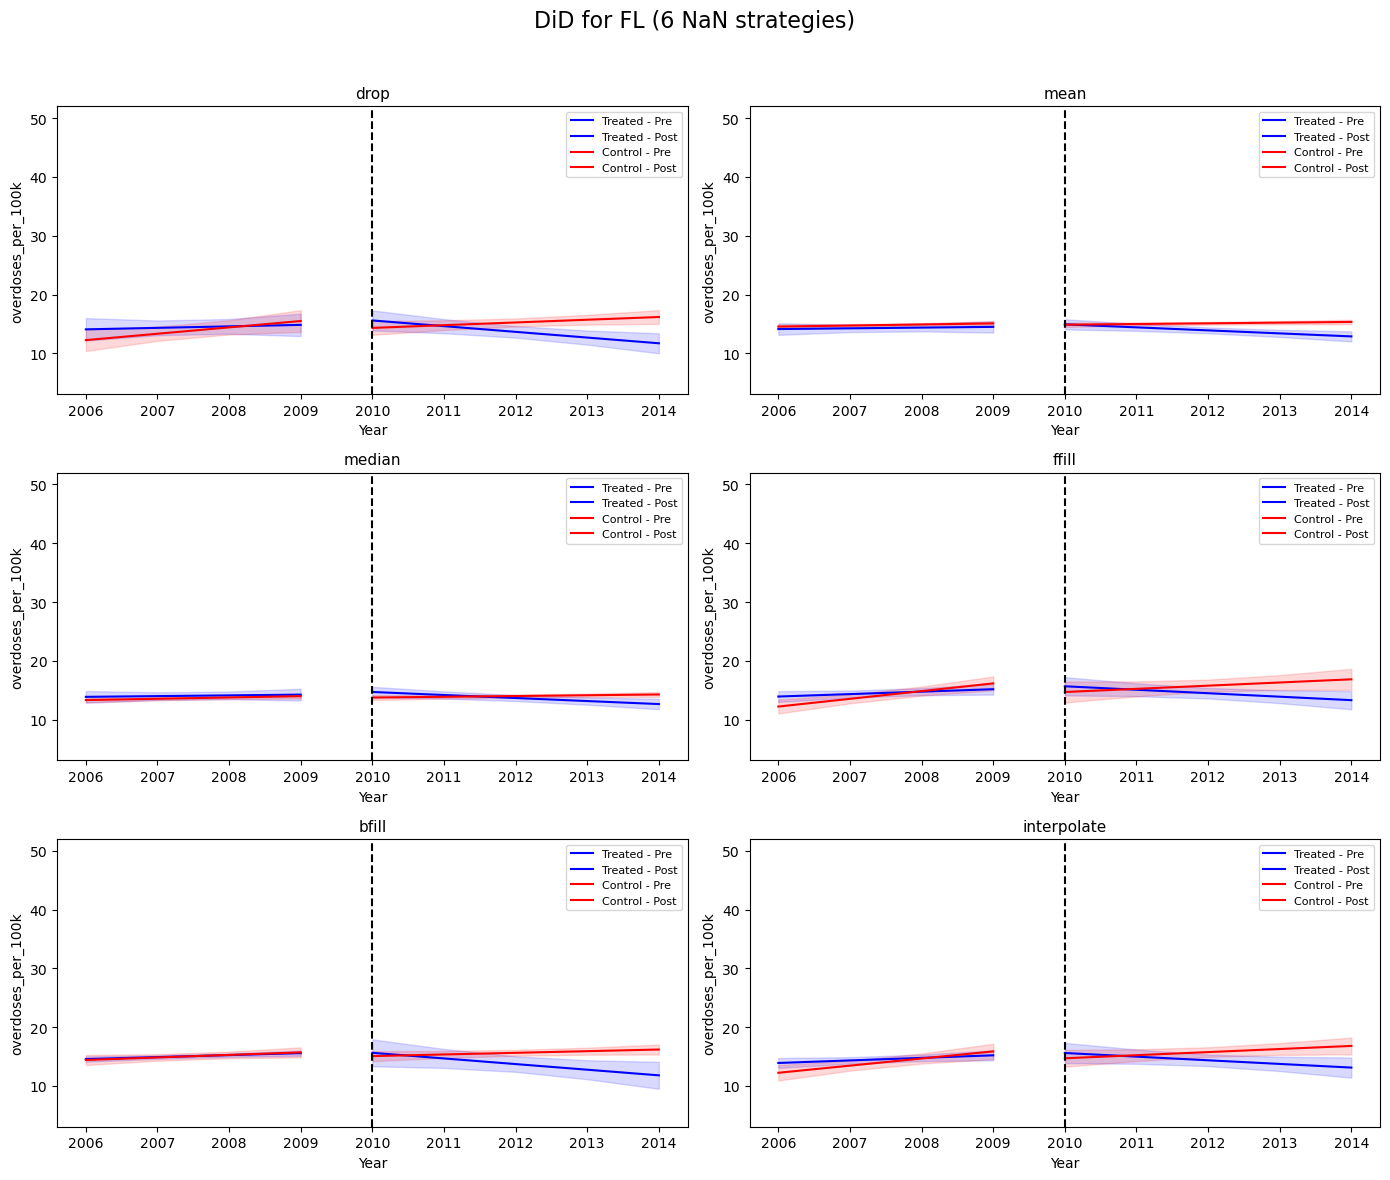

In [38]:
# Florida
plot_did_grid(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
)

WA - drop: DiD estimate = -2.106 in units of overdoses_per_100k
WA - mean: DiD estimate = -0.210 in units of overdoses_per_100k
WA - median: DiD estimate = -0.243 in units of overdoses_per_100k
WA - ffill: DiD estimate = -1.973 in units of overdoses_per_100k
WA - bfill: DiD estimate = -1.284 in units of overdoses_per_100k
WA - interpolate: DiD estimate = -2.045 in units of overdoses_per_100k


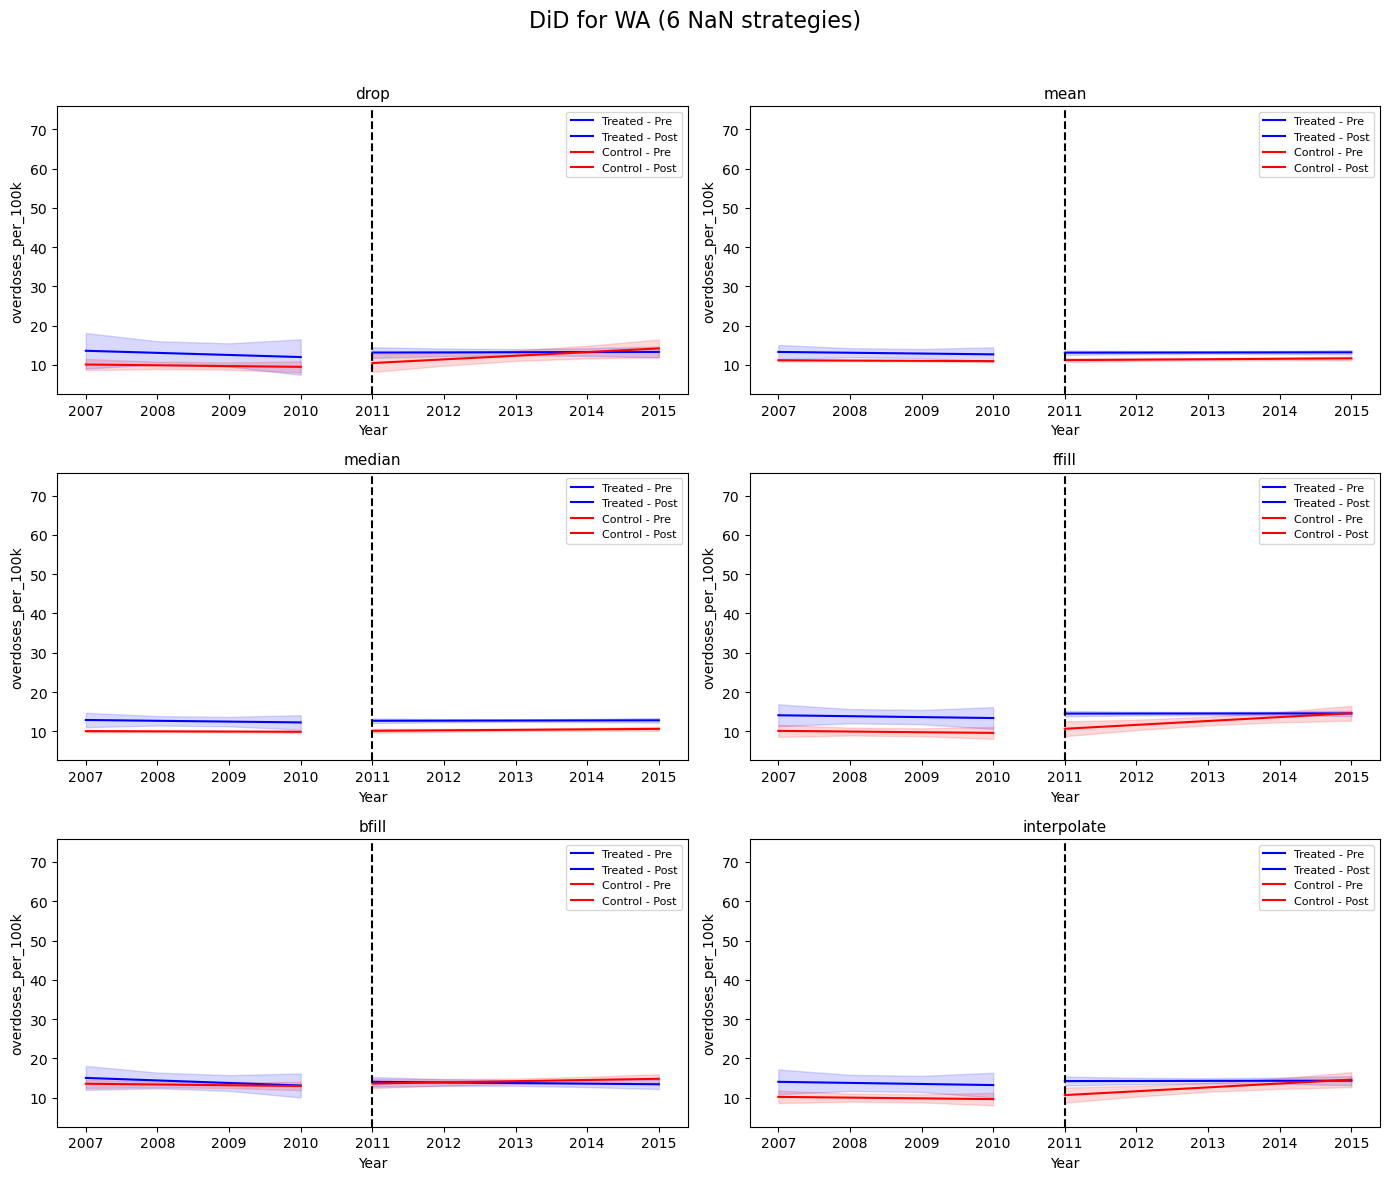

In [39]:
# Washington
plot_did_grid(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
)

## 4. Final Result (for Mortality) (Pending now)

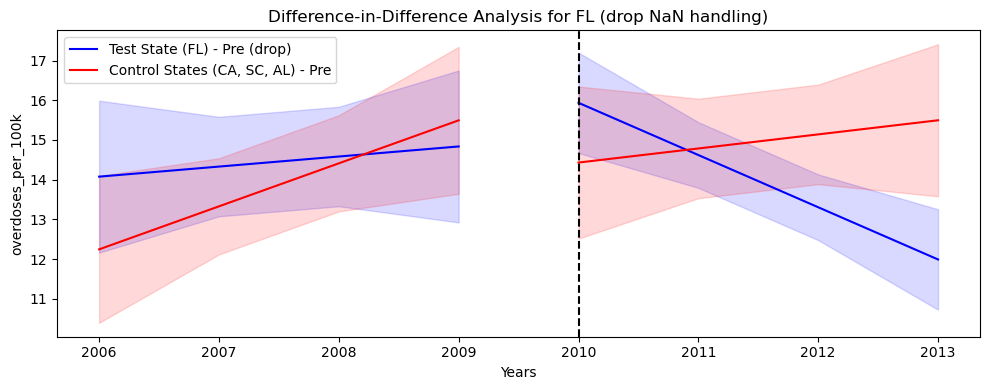

Simple DiD estimate for FL (drop): -1.587 in units of overdoses_per_100k.


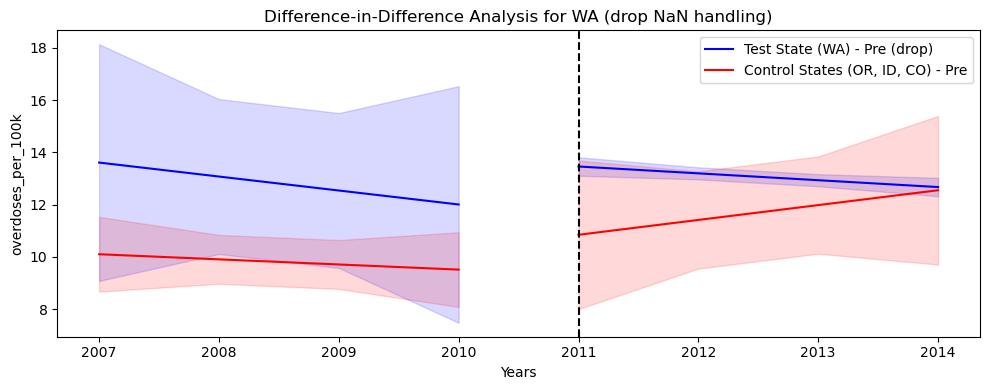

Simple DiD estimate for WA (drop): -1.631 in units of overdoses_per_100k.


In [40]:
# Florida: treated, controls = CA, SC, AL, policy year = 2010
plot_did_for_state(
    df=df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,  # years 2006–2009
    post_window=3,  # years 2010–2013; change to 4 if you want 2014 too
    nan_strategy="drop",
)

# Washington: treated, controls = OR, ID, CO, policy year = 2011
plot_did_for_state(
    df=df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,  # years 2007–2010
    post_window=3,  # years 2011–2014 (or 4 if you want 2015)
    nan_strategy="drop",
)

###############################################################################################################

# Shipment part

## 1. Define plot functions (replace NaN value + plot)

In [41]:
import statsmodels.api as sm
import matplotlib.pyplot as plt


def plot_did_shipment_for_state(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
    nan_strategy="drop",
):
    """
    Difference-in-Differences style plot for shipment outcome (e.g., mme_per_capita),
    with consistent NaN-handling rules across all functions.

    NaN strategies:
      - "drop":        leave NaN as is (they will be dropped later)
      - "mean":        fill NaN with the state-specific mean
      - "median":      fill NaN with the state-specific median
      - "ffill":       forward fill within each time series
                       (within state+county if county exists, else within state)
      - "bfill":       backward fill within each time series
                       (within state+county if county exists, else within state)
      - "interpolate": linear interpolation within each time series
                       (within state+county if county exists, else within state)
    """

    # Normalize states
    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Restrict to treated + control
    use_states = [treated_state] + control_states
    panel = df[df["state"].isin(use_states)].copy()

    # Detect county column
    county_col = "county" if "county" in panel.columns else None

    # ---------------------------
    # NaN handling (consistent)
    # ---------------------------
    if nan_strategy != "drop":

        if nan_strategy in ["mean", "median"]:
            # State-level mean / median replacement
            state_g = panel.groupby("state")[rate_col]

            if nan_strategy == "mean":
                panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))
            else:
                panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))

        else:
            # Time-series methods: ffill, bfill, interpolate
            if county_col:
                panel = panel.sort_values(["state", county_col, "year"])
                group_cols = ["state", county_col]
            else:
                panel = panel.sort_values(["state", "year"])
                group_cols = ["state"]

            g = panel.groupby(group_cols)[rate_col]

            if nan_strategy == "ffill":
                panel[rate_col] = g.transform(lambda s: s.ffill())
            elif nan_strategy == "bfill":
                panel[rate_col] = g.transform(lambda s: s.bfill())
            elif nan_strategy == "interpolate":
                panel[rate_col] = g.transform(lambda s: s.interpolate(method="linear"))
            else:
                raise ValueError("Invalid nan_strategy choice.")

    # ---------------------------
    # Aggregate to state-year
    # ---------------------------
    state_year = (
        panel.groupby(["state", "year"], as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
        .dropna(subset=["rate"])
    )

    # treated dummy
    state_year["treated"] = (state_year["state"] == treated_state).astype(int)

    # treated vs control averages
    group_year = state_year.groupby(["treated", "year"], as_index=False)["rate"].mean()

    # ---------------------------
    # Pre / Post windows
    # ---------------------------
    pre_mask = (group_year["year"] >= policy_year - pre_window) & (
        group_year["year"] < policy_year
    )
    post_mask = (group_year["year"] >= policy_year) & (
        group_year["year"] <= policy_year + post_window
    )

    pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
    pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
    post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
    post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

    if (
        pre_treated.empty
        or pre_control.empty
        or post_treated.empty
        or post_control.empty
    ):
        print(f"Not enough data for given windows / states ({nan_strategy}).")
        return

    # ---------------------------
    # Helper: OLS + CI
    # ---------------------------
    def fit_segment(seg_df):
        seg_df = seg_df.dropna(subset=["rate"])
        X = sm.add_constant(seg_df["year"])
        model = sm.OLS(seg_df["rate"], X).fit()
        preds = model.get_prediction(X)
        mean = preds.predicted_mean
        ci = preds.conf_int(alpha=0.05)
        lower = ci[:, 0]
        upper = ci[:, 1]
        return mean, lower, upper

    tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
    tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
    co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
    co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

    # ---------------------------
    # Plot
    # ---------------------------
    plt.figure(figsize=(10, 4))

    x_pre_tr = pre_treated["year"].to_numpy()
    x_post_tr = post_treated["year"].to_numpy()
    x_pre_co = pre_control["year"].to_numpy()
    x_post_co = post_control["year"].to_numpy()

    # Treated (blue)
    plt.plot(x_pre_tr, tr_pre_mean, color="blue", label="Treated - Pre")
    plt.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

    plt.plot(x_post_tr, tr_post_mean, color="blue", label="Treated - Post")
    plt.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

    # Control (red)
    ctrl_label = f"Control States ({', '.join(control_states)})"
    plt.plot(x_pre_co, co_pre_mean, color="red", label=ctrl_label + " - Pre")
    plt.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

    plt.plot(x_post_co, co_post_mean, color="red", label=ctrl_label + " - Post")
    plt.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

    plt.axvline(policy_year, color="black", linestyle="--")

    plt.title(
        f"Shipment DiD Analysis ({rate_col}) for {treated_state} [{nan_strategy}]"
    )
    plt.xlabel("Year")
    plt.ylabel(rate_col)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    # ---------------------------
    # Numeric DiD estimate
    # ---------------------------
    pre_tr_level = pre_treated["rate"].mean()
    post_tr_level = post_treated["rate"].mean()
    pre_co_level = pre_control["rate"].mean()
    post_co_level = post_control["rate"].mean()

    did_estimate = (post_tr_level - pre_tr_level) - (post_co_level - pre_co_level)

    print(
        f"Shipment DiD estimate for {treated_state} ({nan_strategy}): "
        f"{did_estimate:.3f} in units of {rate_col}."
    )

    return did_estimate

## 2. Compare different NaN value dealing ways (bigger plots)

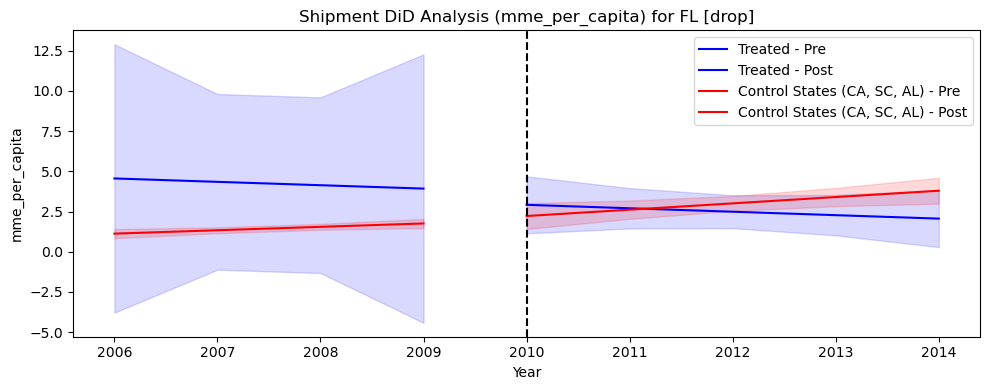

Shipment DiD estimate for FL (drop): -3.317 in units of mme_per_capita.


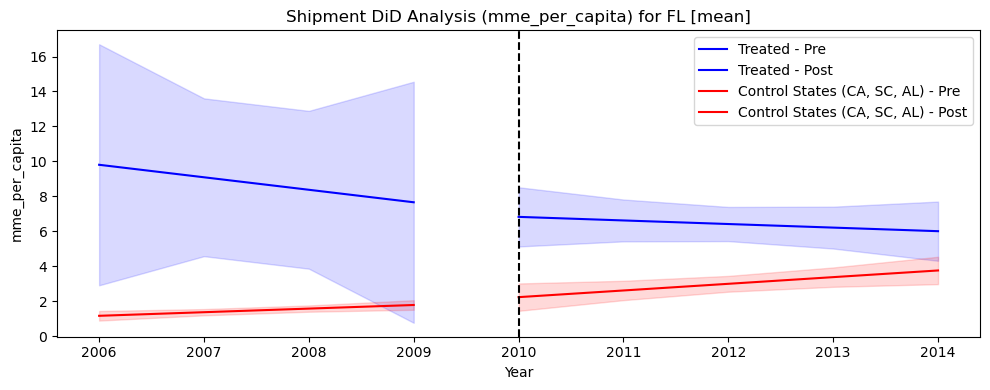

Shipment DiD estimate for FL (mean): -3.839 in units of mme_per_capita.


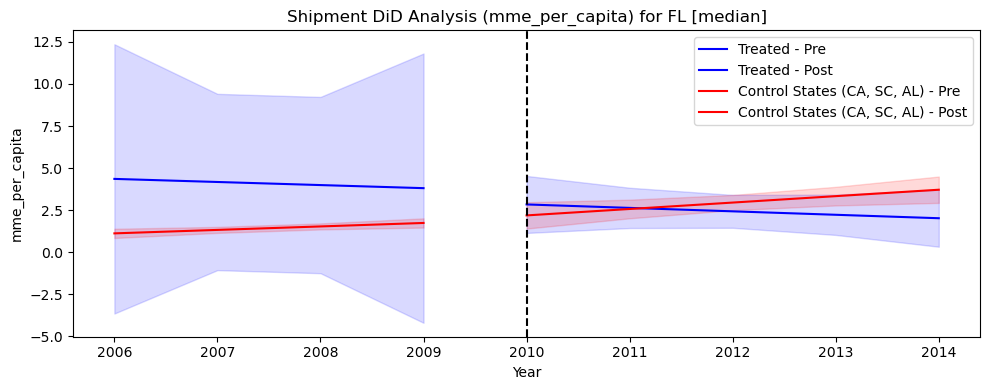

Shipment DiD estimate for FL (median): -3.175 in units of mme_per_capita.


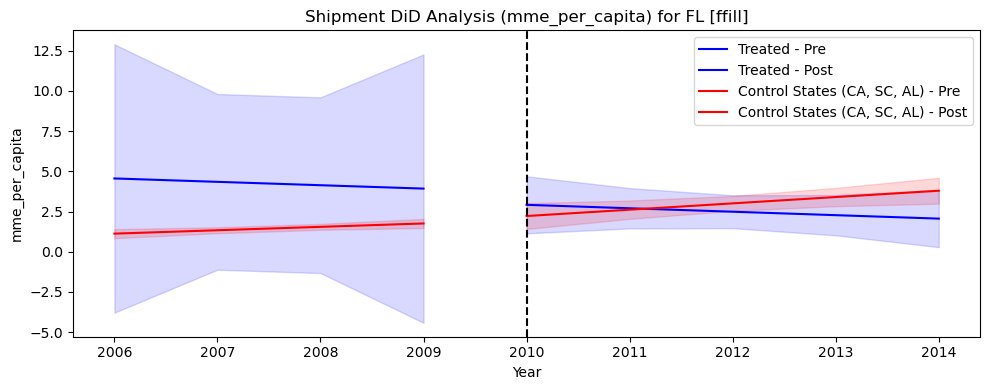

Shipment DiD estimate for FL (ffill): -3.317 in units of mme_per_capita.


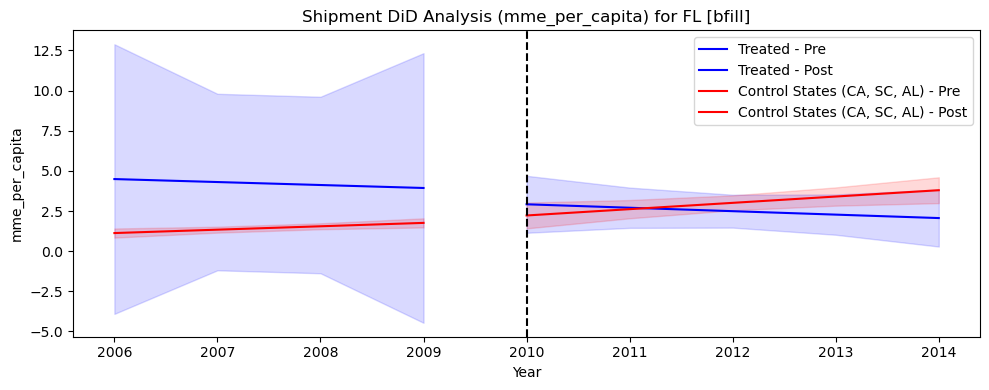

Shipment DiD estimate for FL (bfill): -3.286 in units of mme_per_capita.


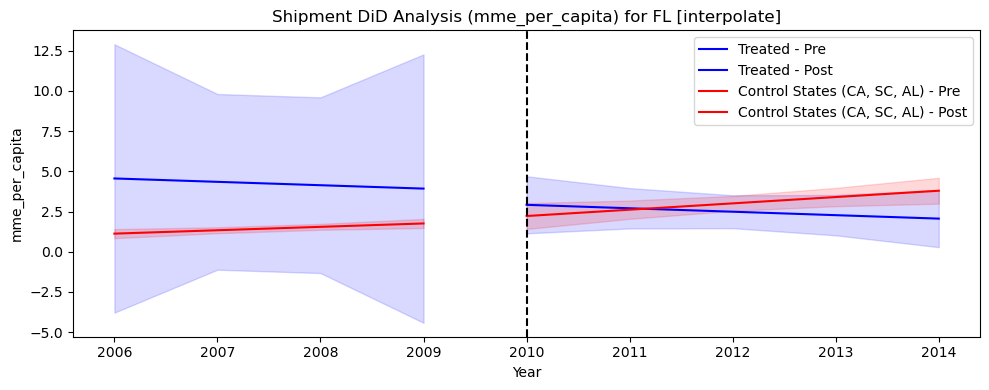

Shipment DiD estimate for FL (interpolate): -3.317 in units of mme_per_capita.


np.float64(-3.316514169743561)

In [42]:
# Florida
# treated = FL, controls = CA, SC, AL, policy year = 2010

# 1. drop
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

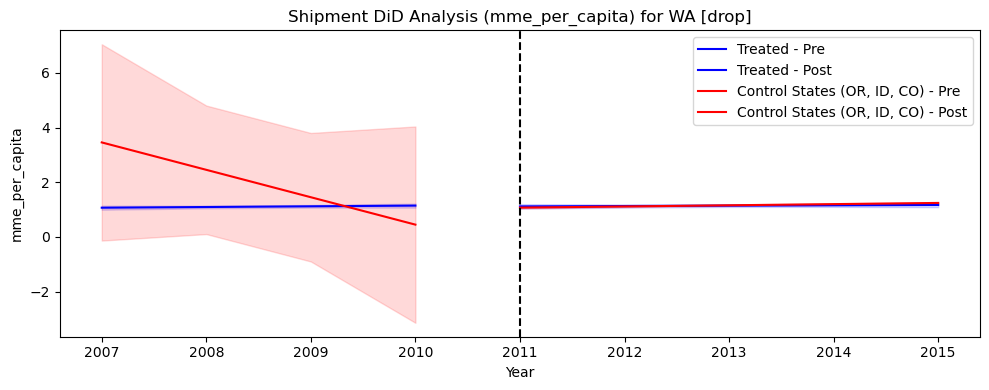

Shipment DiD estimate for WA (drop): 0.832 in units of mme_per_capita.


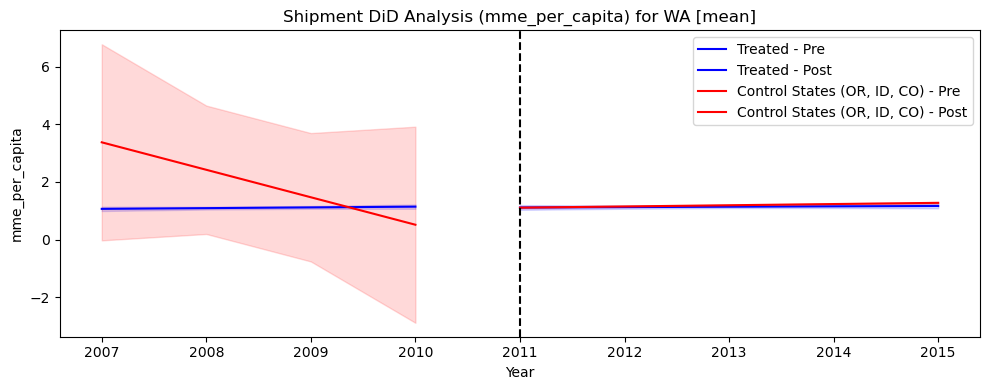

Shipment DiD estimate for WA (mean): 0.791 in units of mme_per_capita.


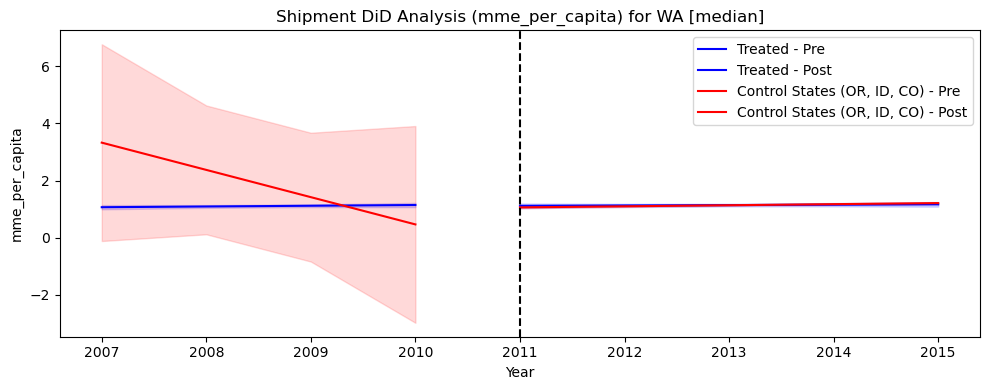

Shipment DiD estimate for WA (median): 0.796 in units of mme_per_capita.


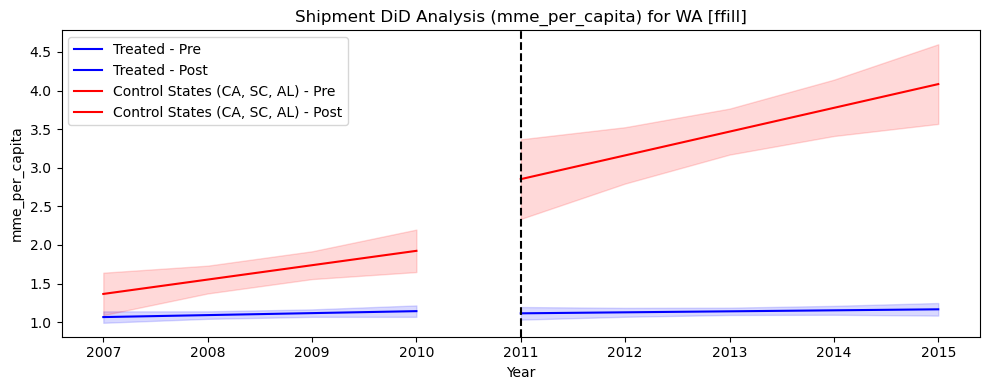

Shipment DiD estimate for WA (ffill): -1.787 in units of mme_per_capita.


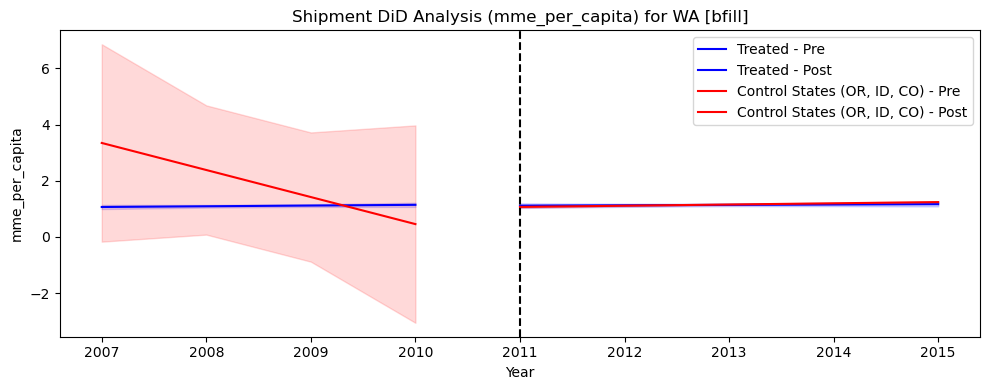

Shipment DiD estimate for WA (bfill): 0.783 in units of mme_per_capita.


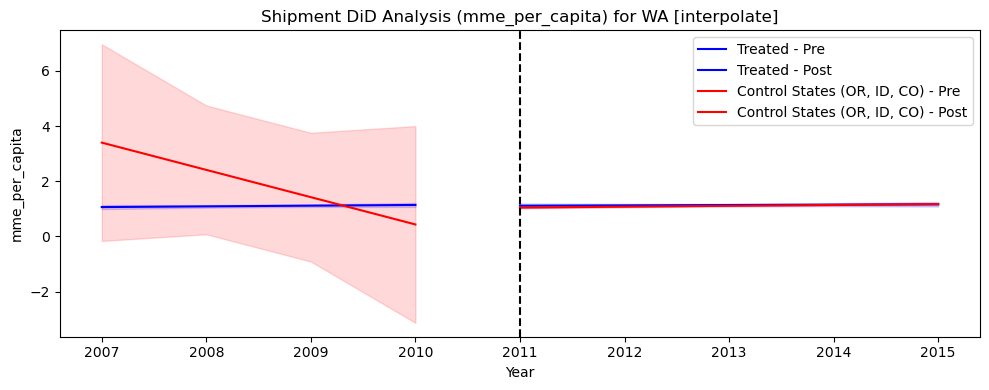

Shipment DiD estimate for WA (interpolate): 0.844 in units of mme_per_capita.


np.float64(0.8435161146062922)

In [43]:
# Washington
# Washington shipment DiD, controls = OR, ID, CO, policy year = 2011

# 1. drop
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["CA", "SC", "AL"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [44]:
import statsmodels.api as sm
import matplotlib.pyplot as plt


def plot_did_shipment_grid(
    df,
    treated_state,
    control_states,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
):
    """
    Draw 6 DiD shipment plots (one for each NaN strategy) in a 3x2 grid.
    NaN strategies follow consistent logic:

      - "drop":        leave NaN as is (they are dropped later)
      - "mean":        fill NaN using state-level mean
      - "median":      fill NaN using state-level median
      - "ffill":       forward-fill within each time series
                       (state+county if county exists, else state only)
      - "bfill":       backward-fill within each time series
                       (state+county if county exists, else state only)
      - "interpolate": linear interpolation within each time series
                       (state+county if county exists, else state only)
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    # Normalize state codes
    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df.copy()
    df["state"] = df["state"].str.upper()

    # Keep only the selected set of states
    use_states = [treated_state] + control_states
    subset = df[df["state"].isin(use_states)].copy()

    # Detect county column for panel data
    county_col = "county" if "county" in subset.columns else None

    if subset.empty:
        print(f"No data found for treated/control states: {use_states}")
        return

    # Create the 3x2 grid
    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    # ---------- Helper: Fit OLS + CI ----------
    def fit_segment(seg_df):
        X = sm.add_constant(seg_df["year"])
        model = sm.OLS(seg_df["rate"], X).fit()
        preds = model.get_prediction(X)
        mean = preds.predicted_mean
        ci = preds.conf_int(alpha=0.05)
        return mean, ci[:, 0], ci[:, 1]

    # ---------- Loop through NaN strategies ----------
    for i, strat in enumerate(strategies):
        ax = axes[i]
        panel = subset.copy()

        # ----------------------------------------------
        # 1. NaN handling (consistent with other functions)
        # ----------------------------------------------
        if strat != "drop":

            # Mean / median at state level
            if strat in ["mean", "median"]:
                state_g = panel.groupby("state")[rate_col]

                if strat == "mean":
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))
                else:
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))

            else:
                # Time-series fill: ffill, bfill, interpolate
                if county_col:
                    # Fill within (state, county)
                    panel = panel.sort_values(["state", county_col, "year"])
                    group_cols = ["state", county_col]
                else:
                    # Fill within each state
                    panel = panel.sort_values(["state", "year"])
                    group_cols = ["state"]

                g = panel.groupby(group_cols)[rate_col]

                if strat == "ffill":
                    panel[rate_col] = g.transform(lambda s: s.ffill())
                elif strat == "bfill":
                    panel[rate_col] = g.transform(lambda s: s.bfill())
                elif strat == "interpolate":
                    panel[rate_col] = g.transform(
                        lambda s: s.interpolate(method="linear")
                    )
                else:
                    ax.set_title(f"{strat} (invalid strategy)")
                    ax.axis("off")
                    continue

        # ----------------------------------------------
        # 2. Aggregate to state-year level
        # ----------------------------------------------
        state_year = (
            panel.groupby(["state", "year"], as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        if state_year.empty:
            ax.set_title(f"{strat} (no usable data)")
            ax.axis("off")
            continue

        # Mark treated vs control
        state_year["treated"] = (state_year["state"] == treated_state).astype(int)

        # Average across states within each group-year
        group_year = state_year.groupby(["treated", "year"], as_index=False)[
            "rate"
        ].mean()

        # ----------------------------------------------
        # 3. Split into pre/post segments
        # ----------------------------------------------
        pre_mask = (group_year["year"] >= policy_year - pre_window) & (
            group_year["year"] < policy_year
        )
        post_mask = (group_year["year"] >= policy_year) & (
            group_year["year"] <= policy_year + post_window
        )

        pre_treated = group_year[pre_mask & (group_year["treated"] == 1)].copy()
        pre_control = group_year[pre_mask & (group_year["treated"] == 0)].copy()
        post_treated = group_year[post_mask & (group_year["treated"] == 1)].copy()
        post_control = group_year[post_mask & (group_year["treated"] == 0)].copy()

        if (
            pre_treated.empty
            or pre_control.empty
            or post_treated.empty
            or post_control.empty
        ):
            ax.set_title(f"{strat} (insufficient window data)")
            ax.axis("off")
            continue

        # ----------------------------------------------
        # 4. Fit trends for plotting
        # ----------------------------------------------
        tr_pre_mean, tr_pre_low, tr_pre_high = fit_segment(pre_treated)
        tr_post_mean, tr_post_low, tr_post_high = fit_segment(post_treated)
        co_pre_mean, co_pre_low, co_pre_high = fit_segment(pre_control)
        co_post_mean, co_post_low, co_post_high = fit_segment(post_control)

        x_pre_tr = pre_treated["year"].to_numpy()
        x_post_tr = post_treated["year"].to_numpy()
        x_pre_co = pre_control["year"].to_numpy()
        x_post_co = post_control["year"].to_numpy()

        # ----------------------------------------------
        # 5. Plot treated (blue) and control (red)
        # ----------------------------------------------
        ax.plot(x_pre_tr, tr_pre_mean, color="blue", label="Treated (pre)")
        ax.fill_between(x_pre_tr, tr_pre_low, tr_pre_high, color="blue", alpha=0.15)

        ax.plot(x_post_tr, tr_post_mean, color="blue", label="Treated (post)")
        ax.fill_between(x_post_tr, tr_post_low, tr_post_high, color="blue", alpha=0.15)

        ax.plot(x_pre_co, co_pre_mean, color="red", label="Control (pre)")
        ax.fill_between(x_pre_co, co_pre_low, co_pre_high, color="red", alpha=0.15)

        ax.plot(x_post_co, co_post_mean, color="red", label="Control (post)")
        ax.fill_between(x_post_co, co_post_low, co_post_high, color="red", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(strat, fontsize=11)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)
        ax.legend(fontsize=8, loc="best")

    # Turn off any unused axes
    for j in range(len(strategies), len(axes)):
        axes[j].axis("off")

    fig.suptitle(
        f"Shipment DiD for {treated_state} ({rate_col}) — 6 NaN strategies",
        fontsize=16,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

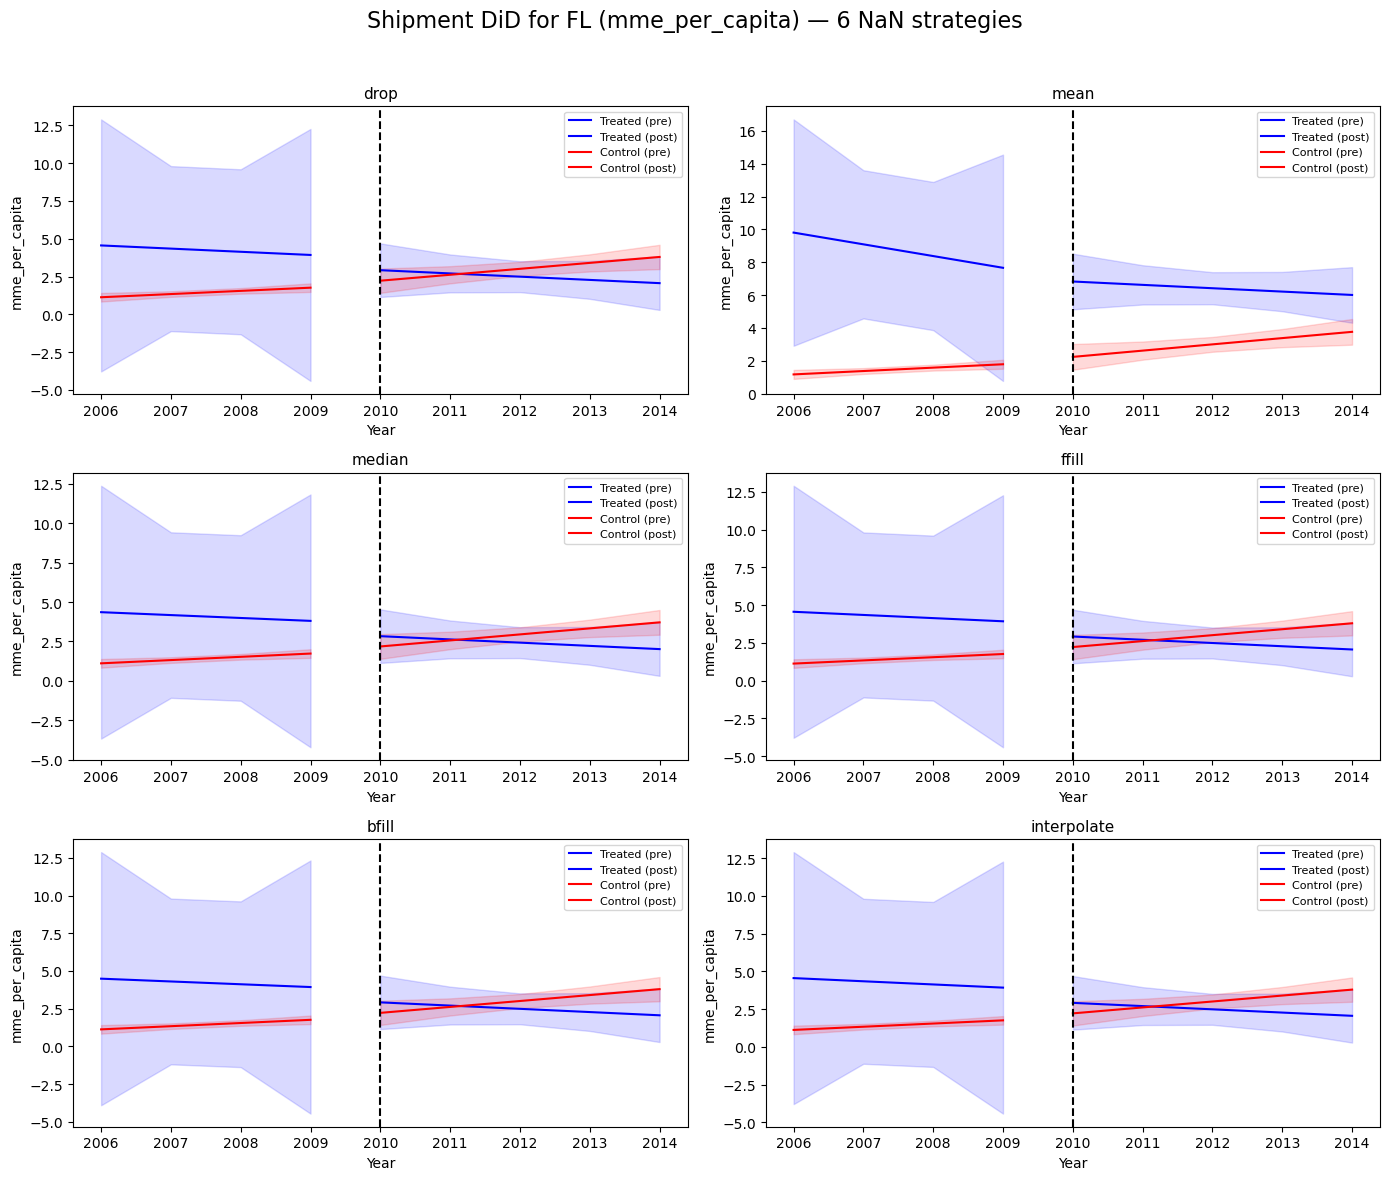

In [45]:
# Florida
plot_did_shipment_grid(
    df,
    treated_state="FL",
    control_states=["CA", "SC", "AL"],
    policy_year=2010,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
)

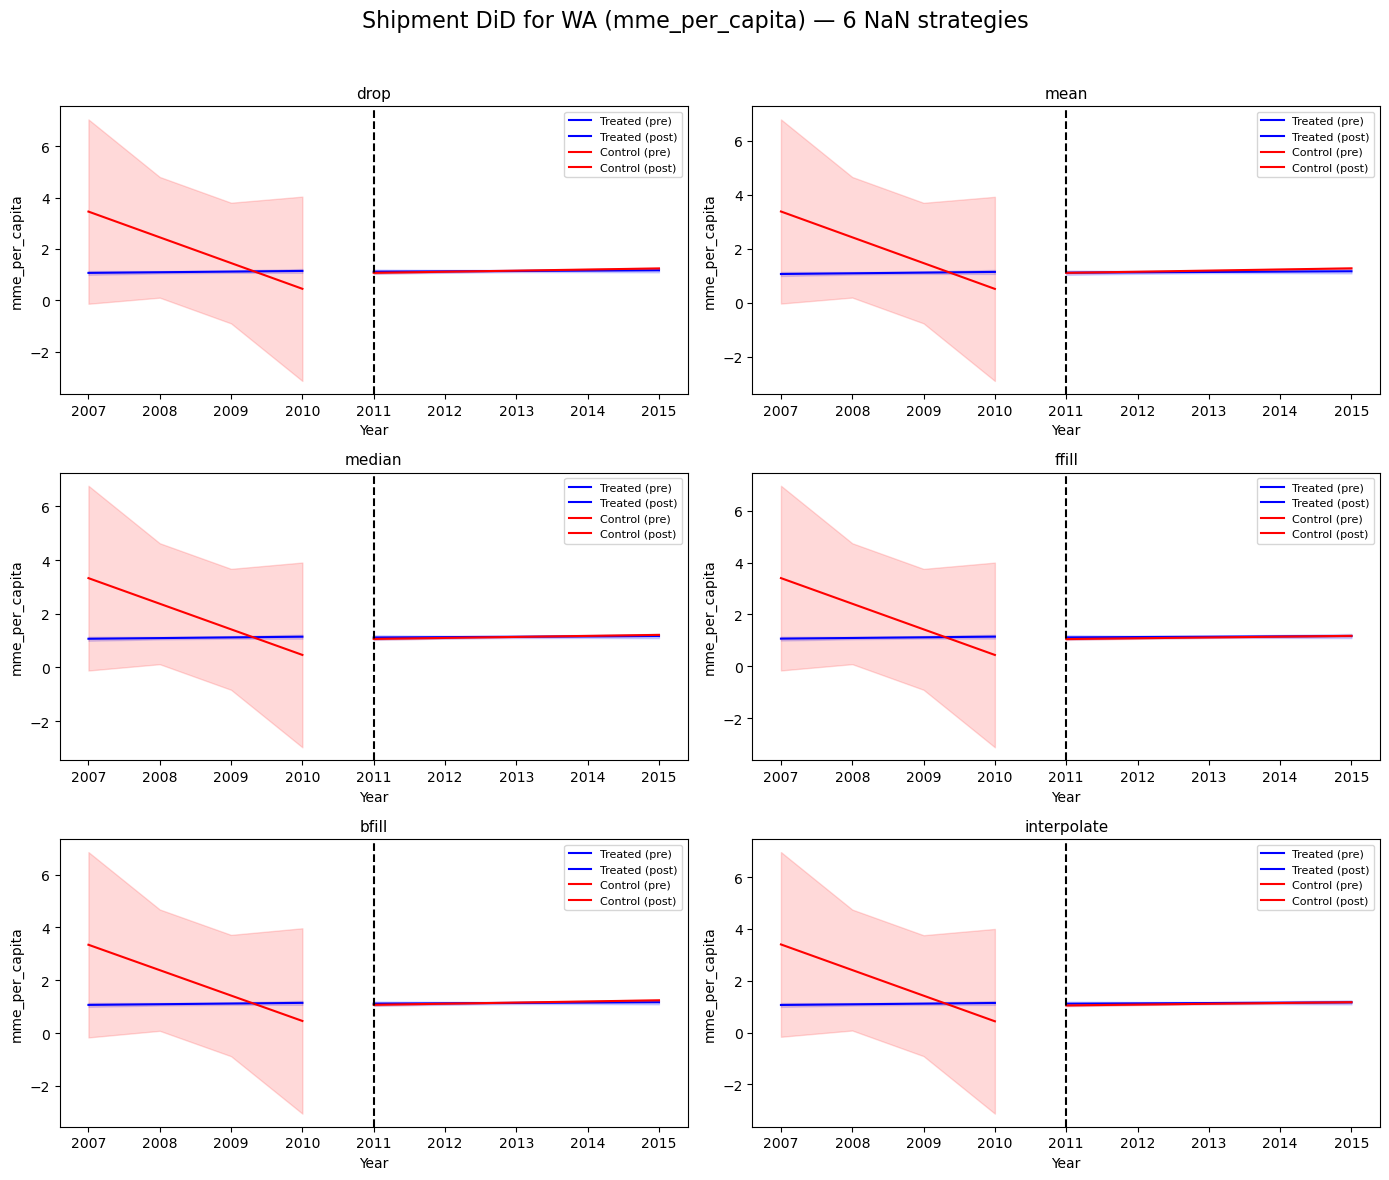

In [46]:
# Washington
plot_did_shipment_grid(
    df,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2011,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=4,
)

## 4. Final Result (for Mortality) (Backfill)

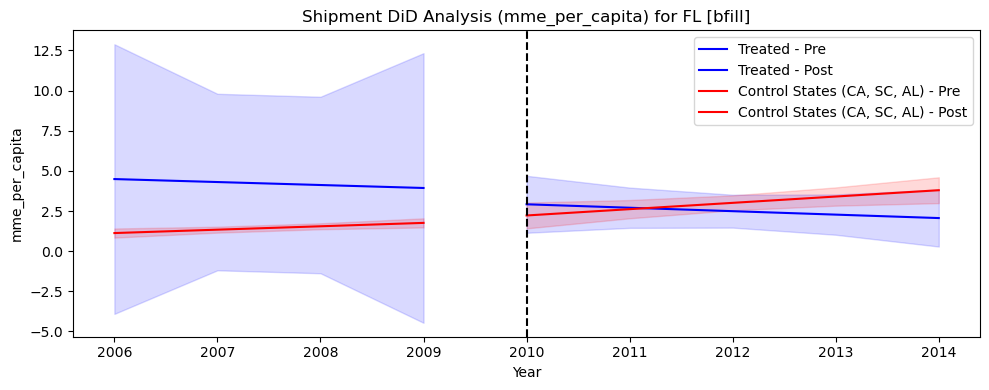

Shipment DiD estimate for FL (bfill): -3.286 in units of mme_per_capita.


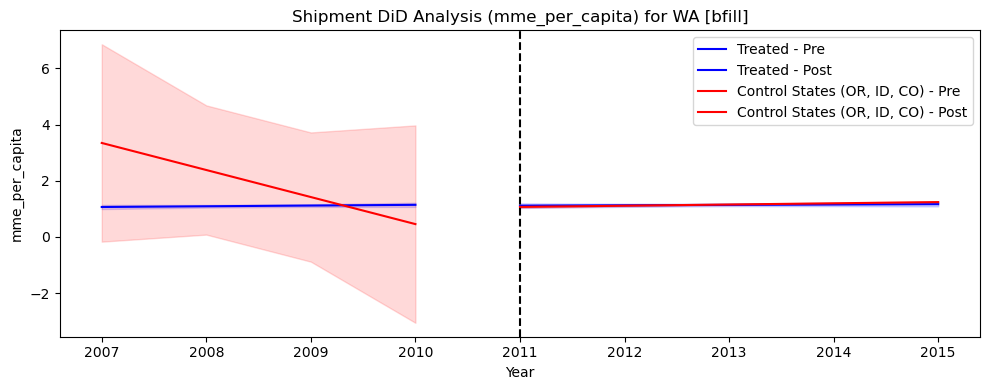

Shipment DiD estimate for WA (bfill): 0.783 in units of mme_per_capita.


,state,controls,nan_strategy,did_estimate
0,FL,"CA, SC, AL",bfill,-3.286167
1,WA,"OR, ID, CO",bfill,0.782842


In [47]:
PREFERRED_STRATEGY = "bfill"
RATE_COL = "mme_per_capita"

FL_CONTROLS = ["CA", "SC", "AL"]
WA_CONTROLS = ["OR", "ID", "CO"]

# Florida: treated FL, controls CA/SC/AL, policy year 2010
did_FL_bfill = plot_did_shipment_for_state(
    df,
    treated_state="FL",
    control_states=FL_CONTROLS,
    policy_year=2010,
    rate_col=RATE_COL,
    nan_strategy=PREFERRED_STRATEGY,
)

# Washington: treated WA, controls OR/ID/CO, policy year 2011
did_WA_bfill = plot_did_shipment_for_state(
    df,
    treated_state="WA",
    control_states=WA_CONTROLS,
    policy_year=2011,
    rate_col=RATE_COL,
    nan_strategy=PREFERRED_STRATEGY,
)

# Collect results into a small summary table for the report
did_summary = pd.DataFrame(
    [
        {
            "state": "FL",
            "controls": ", ".join(FL_CONTROLS),
            "nan_strategy": PREFERRED_STRATEGY,
            "did_estimate": did_FL_bfill,
        },
        {
            "state": "WA",
            "controls": ", ".join(WA_CONTROLS),
            "nan_strategy": PREFERRED_STRATEGY,
            "did_estimate": did_WA_bfill,
        },
    ]
)

did_summary

================================================================================================

# FIX shipment parts

Original df columns:
Index(['state', 'county', 'population', 'year', 'total_grams', 'total_pills',
       'total_mme', 'n_transactions', 'drug_deaths', 'missing_deaths',
       'mme_per_capita', 'pills_per_capita', 'overdoses_per_100k',
       'log_mme_per_capita', 'log_overdoses_per_100k'],
      dtype='object')

Example rows for FL (state-year, MKE per 1M):
   state  year  mke_per_1M
20    FL  2006    0.013854
21    FL  2007    0.011842
22    FL  2008    0.022489
23    FL  2009    0.006233
24    FL  2010    0.010195


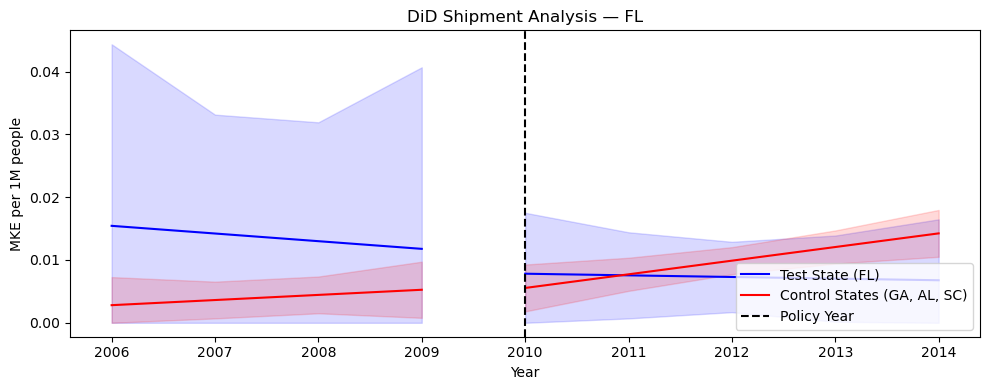

DiD Estimate for FL: -0.0122 (MKE per 1M people)


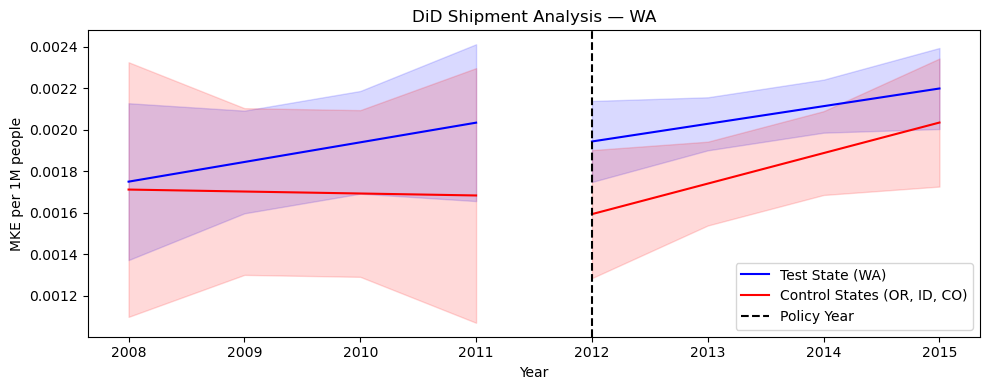

DiD Estimate for WA: 0.0001 (MKE per 1M people)
FL DiD: -0.012169862914090257
WA DiD: 6.264254723229259e-05


In [48]:
# ==========================================================
# 0. Imports
# ==========================================================
import numpy as np
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# ==========================================================
# 1. Load county-year panel and build state-year MKE per 1M
# ==========================================================
project_root = Path("..")
input_path = project_root / "00_data" / "processed" / "new_master_county_year_panel.csv"

df = pd.read_csv(input_path)

print("Original df columns:")
print(df.columns)

# We only need these columns for shipment analysis
required_cols = ["state", "county", "year", "total_mme", "population"]
for col in required_cols:
    if col not in df.columns:
        raise ValueError(
            f"Missing column {col}. Please check new_master_county_year_panel.csv."
        )

# Clean basic types
df["state"] = df["state"].astype(str)
df["county"] = df["county"].astype(str)
df["year"] = df["year"].astype(int)

# Sanity check: total_mme and population should be non-negative
if (df["total_mme"] < 0).any():
    print("WARNING: Found negative total_mme values. They will be set to NaN.")
    df.loc[df["total_mme"] < 0, "total_mme"] = np.nan

if (df["population"] <= 0).any():
    print("WARNING: Found non-positive population values. They will be set to NaN.")
    df.loc[df["population"] <= 0, "population"] = np.nan

# ----------------------------------------------------------
# Aggregate county-year → state-year
# ----------------------------------------------------------
state_year = df.groupby(["state", "year"], as_index=False).agg(
    total_mme_state=("total_mme", "sum"),
    total_pop_state=("population", "sum"),
)

# mg per person
state_year["mme_per_capita_mg"] = (
    state_year["total_mme_state"] / state_year["total_pop_state"]
)

# Define "MKE per 1M people" here
# If total_mme is in mg, then: (mg / person) / 1000 = MKE per 1M people
state_year["mke_per_1M"] = state_year["mme_per_capita_mg"] / 1000.0

# Keep only the columns we need
state_year = state_year[["state", "year", "mke_per_1M"]].copy()

print("\nExample rows for FL (state-year, MKE per 1M):")
print(state_year[state_year["state"] == "FL"].head())

# Ensure no negative values
state_year["mke_per_1M"] = state_year["mke_per_1M"].clip(lower=0.0)


# ==========================================================
# 2. DiD plotting function (state-year level, linear trend + CI)
#     — Unit: MKE per 1M people
# ==========================================================
def plot_did_shipment_for_state(
    df_state: pd.DataFrame,
    treated_state: str,
    control_states,
    policy_year: int,
    rate_col: str = "mke_per_1M",
    pre_window: int = 4,
    post_window: int = 4,
    nan_strategy: str = "bfill",
):
    """
    Difference-in-Differences style plot for shipment outcome
    (MKE per 1M people), with linear trends and 95% confidence intervals.

    df_state      : state-year DataFrame with columns ['state', 'year', rate_col]
    treated_state : treated state abbreviation, e.g. 'FL'
    control_states: list of control state abbreviations, e.g. ['GA', 'AL', 'SC']
    policy_year   : year of policy implementation (vertical dashed line)
    rate_col      : rate variable name (default: 'mke_per_1M')
    pre_window    : number of pre-policy years to include
    post_window   : number of post-policy years to include
    nan_strategy  : 'bfill' (default), 'ffill', 'mean', 'median', 'drop'
    """

    treated_state = treated_state.upper()
    control_states = [s.upper() for s in control_states]

    df = df_state.copy()
    df["state"] = df["state"].str.upper()

    # Keep treated + control states only
    panel = df[df["state"].isin([treated_state] + control_states)].copy()

    # --------------------
    # NaN handling
    # --------------------
    if nan_strategy in ("bfill", "ffill"):
        panel = panel.sort_values(["state", "year"])
        if nan_strategy == "bfill":
            panel[rate_col] = panel.groupby("state")[rate_col].bfill()
        else:
            panel[rate_col] = panel.groupby("state")[rate_col].ffill()

    elif nan_strategy in ("mean", "median"):
        if nan_strategy == "mean":
            panel[rate_col] = panel.groupby("state")[rate_col].transform(
                lambda x: x.fillna(x.mean())
            )
        else:
            panel[rate_col] = panel.groupby("state")[rate_col].transform(
                lambda x: x.fillna(x.median())
            )

    elif nan_strategy == "drop":
        panel = panel.dropna(subset=[rate_col])

    else:
        raise ValueError(
            "nan_strategy must be one of: 'bfill', 'ffill', 'mean', 'median', 'drop'"
        )

    panel = panel.dropna(subset=[rate_col])
    panel[rate_col] = panel[rate_col].clip(lower=0.0)

    # ------------------------------------------------------
    # Build a clean state-year panel: one observation per state-year
    # ------------------------------------------------------
    state_year_clean = (
        panel.groupby(["state", "year"], as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )
    state_year_clean["treated"] = (state_year_clean["state"] == treated_state).astype(
        int
    )

    # Get average by treated-status × year
    grp = (
        state_year_clean.groupby(["treated", "year"], as_index=False)["rate"]
        .mean()
        .sort_values(["treated", "year"])
    )

    # ------------------------------------------------------
    # Define pre/post windows
    # ------------------------------------------------------
    pre = grp[(grp["year"] >= policy_year - pre_window) & (grp["year"] < policy_year)]
    post = grp[
        (grp["year"] >= policy_year) & (grp["year"] <= policy_year + post_window)
    ]

    pre_t = pre[pre["treated"] == 1].copy()
    post_t = post[post["treated"] == 1].copy()
    pre_c = pre[pre["treated"] == 0].copy()
    post_c = post[post["treated"] == 0].copy()

    if pre_t.empty or post_t.empty or pre_c.empty or post_c.empty:
        print(f"[{treated_state}] Not enough data for the given windows.")
        return None

    # ------------------------------------------------------
    # Helper for OLS + 95% CI, with year centered & CI ≥ 0
    # ------------------------------------------------------
    def fit_with_ci(seg: pd.DataFrame):
        """
        Fit OLS(rate ~ year_c) with year centered to stabilize CI.
        Returns mean prediction and 95% CI (mean_ci_lower, mean_ci_upper).
        """

        seg = seg.dropna(subset=["rate"]).copy()

        # Center year to avoid inflated variance
        seg["year_c"] = seg["year"] - seg["year"].mean()

        X = sm.add_constant(seg["year_c"])
        model = sm.OLS(seg["rate"], X).fit()

        pred = model.get_prediction(X)
        sf = pred.summary_frame(alpha=0.05)  # 95% CI for mean

        mean = sf["mean"].values
        lower = sf["mean_ci_lower"].values
        upper = sf["mean_ci_upper"].values

        # Clip lower bound & mean at 0 (no negative MKE)
        mean = np.clip(mean, 0.0, None)
        lower = np.clip(lower, 0.0, None)

        return mean, lower, upper

    # Fit linear trend + CI for each segment
    tr_pre_m, tr_pre_l, tr_pre_h = fit_with_ci(pre_t)
    tr_post_m, tr_post_l, tr_post_h = fit_with_ci(post_t)
    co_pre_m, co_pre_l, co_pre_h = fit_with_ci(pre_c)
    co_post_m, co_post_l, co_post_h = fit_with_ci(post_c)

    # ------------------------------------------------------
    # Plot (colors and units aligned with Figure 2)
    # ------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 4))

    # Treated (Test State, blue)
    ax.plot(pre_t["year"], tr_pre_m, color="blue")
    ax.fill_between(pre_t["year"], tr_pre_l, tr_pre_h, color="blue", alpha=0.15)

    ax.plot(post_t["year"], tr_post_m, color="blue")
    ax.fill_between(post_t["year"], tr_post_l, tr_post_h, color="blue", alpha=0.15)

    # Control (red)
    ax.plot(pre_c["year"], co_pre_m, color="red")
    ax.fill_between(pre_c["year"], co_pre_l, co_pre_h, color="red", alpha=0.15)

    ax.plot(post_c["year"], co_post_m, color="red")
    ax.fill_between(post_c["year"], co_post_l, co_post_h, color="red", alpha=0.15)

    # Policy year vertical line
    ax.axvline(policy_year, linestyle="--", color="black")

    # Legend same as Figure 2: Test / Control / Policy Year only
    test_line = mlines.Line2D(
        [], [], color="blue", label=f"Test State ({treated_state})"
    )
    ctrl_line = mlines.Line2D(
        [], [], color="red", label=f"Control States ({', '.join(control_states)})"
    )
    policy_line = mlines.Line2D(
        [], [], color="black", linestyle="--", label="Policy Year"
    )
    ax.legend(handles=[test_line, ctrl_line, policy_line], loc="lower right")

    ax.set_title(f"DiD Shipment Analysis — {treated_state}")
    ax.set_ylabel("MKE per 1M people")  # Same unit as Figure 2
    ax.set_xlabel("Year")
    fig.tight_layout()
    plt.show()

    # ------------------------------------------------------
    # Numeric DiD estimate (mean-level DiD using year-level means)
    # ------------------------------------------------------
    pre_t_mean = pre_t["rate"].mean()
    post_t_mean = post_t["rate"].mean()
    pre_c_mean = pre_c["rate"].mean()
    post_c_mean = post_c["rate"].mean()

    did = (post_t_mean - pre_t_mean) - (post_c_mean - pre_c_mean)

    print(f"DiD Estimate for {treated_state}: {did:.4f} " "(MKE per 1M people)")
    return did


# ==========================================================
# 3. Run DiD for FL and WA
# ==========================================================
did_fl = plot_did_shipment_for_state(
    df_state=state_year,
    treated_state="FL",
    control_states=["GA", "AL", "SC"],
    policy_year=2010,
    rate_col="mke_per_1M",  # Use the same unit
    pre_window=4,
    post_window=4,
    nan_strategy="bfill",
)

did_wa = plot_did_shipment_for_state(
    df_state=state_year,
    treated_state="WA",
    control_states=["OR", "ID", "CO"],
    policy_year=2012,
    rate_col="mke_per_1M",
    pre_window=4,
    post_window=4,
    nan_strategy="bfill",
)

print("FL DiD:", did_fl)
print("WA DiD:", did_wa)